# Lab 3: Tree ensembles (100,000 training rows)

Run in **lab3_deadline** using **Python (lab2)**. This deadline version uses **100,000 training rows**, stratified by the original attack labels with seed 42. It keeps the full original validation (378,354 rows) and test (378,355 rows) sets, and the Lab 2 complete-feature preprocessor. All six compared binary models are fitted on the same sampled training rows. This is a reduced-training experiment, not a full-training run. The original full-data Lab 2 and Lab 3 checkpoints are preserved separately.

This is an educational CICIDS2017 comparison, not a production IDS or evidence of generalization to a new organization. No report conclusions are inserted before execution.

Predeclared model rules: seed 42; forest candidates 100/300 trees, sqrt(d)/d predictors, baseline minimum leaf/5; practical tie tolerance 0.0001 balanced accuracy, preferring fewer trees then fewer nodes. Both boosting methods use learning rates 0.03/0.10, depths 1/3, up to 500 rounds, and validation-log-loss early stopping after 20 rounds without improvement. XGBoost additionally tests lambda 0/1/10 and gamma 0/0.1. Every boosting round uses the entire 100,000-row training subset and all predictors. The worker limit changed from fourteen to six for responsiveness, then to twelve at the user's request. Completed models are reused. Cost measurements use the final twelve-worker limit, with a fresh selected RF fit for consistent timing. Standard GB is serial.

Bagging is represented by a bootstrapped forest with **all d predictors at every split** and the Lab 2 tree-size setting. The identical RF d/baseline-leaf candidate shares that fit. This is mathematical model reuse, not omitting a grid row. The other RF candidates introduce random feature selection and/or a larger minimum leaf.

The raw-feature importance comparison groups all one-hot port columns as one destination-port feature. Permuting that whole block keeps valid one-hot rows. It evaluates every validation row, three repeats for each of all 69 eligible raw predictors. Encoded-column MDI rankings are saved separately.

Reference: [assignment](Lab3.pdf), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html), [XGBoost early stopping](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.callback.EarlyStopping).


In [1]:
%matplotlib inline
from pathlib import Path
import copy, gc, hashlib, json, platform, time
import cloudpickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from scipy.special import expit
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, log_loss, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping
import sklearn, scipy, xgboost

source = Path("../lab2_2")
inputs = source / "lab3_inputs"
out = Path("notebook_results")
out.mkdir(exist_ok=True)
models = out / "models"
models.mkdir(exist_ok=True)
SEED, THREADS, MAX_ROUNDS, PATIENCE, TIE = 42, 12, 500, 20, 0.0001
thread_limit = threadpool_limits(limits=THREADS)
manifest = json.loads((inputs / "manifest.json").read_text())
assert manifest["status"] == "complete"

def save(table, name):
    display(table)
    table.to_csv(out / (name + ".csv"), index=False)

def figure(name):
    plt.tight_layout()
    plt.savefig(out / (name + ".png"), dpi=180)
    plt.show()
    plt.close()

def dump(model, name):
    path = models / (name + ".pkl")
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as file:
        cloudpickle.dump(model, file)
    temporary.replace(path)

def load(name):
    with (models / (name + ".pkl")).open("rb") as file:
        return cloudpickle.load(file)

def progress(stage, **values):
    (out / "latest.json").write_text(json.dumps({"stage": stage, "time": time.time(), **values}, indent=2))

def confusion(truth, prediction, name, labels=None):
    fig, ax = plt.subplots(figsize=(3.2, 2.8) if labels is None else (7, 6))
    ConfusionMatrixDisplay.from_predictions(truth, prediction, labels=labels, normalize="true",
        include_values=labels is None, colorbar=labels is not None, values_format=".3f",
        display_labels=None if labels is None else [str(v).replace("�", "-") for v in labels],
        xticks_rotation=90, ax=ax)
    ax.set_title(name)
    ax.tick_params(labelsize=8)
    figure(name)

data = {name: pd.read_csv(inputs / ("y_" + name + ".csv")) for name in ["train", "validation", "test"]}
features = pd.read_csv(inputs / "encoded_features.csv").encoded_feature.tolist()
x_train = sparse.load_npz(inputs / "X_train.npz")
x_val = sparse.load_npz(inputs / "X_validation.npz")
y_train = data["train"].binary_label.to_numpy()
y_val = data["validation"].binary_label.to_numpy()
for name in data:
    ids = pd.read_csv(inputs / (name + "_ids.csv")).row_id
    np.testing.assert_array_equal(ids, data[name].row_id)
assert x_train.shape == (len(y_train), len(features))
assert x_val.shape == (len(y_val), len(features))
d = len(features)
n_numeric = len(manifest["numerical_features"])
chosen = train_test_split(np.arange(len(y_train)), train_size=100000,
    stratify=data["train"].multiclass_label, random_state=SEED)[0]
chosen.sort()
data["train"] = data["train"].iloc[chosen].reset_index(drop=True)
x_train = x_train[chosen]
y_train = data["train"].binary_label.to_numpy()
data["train"].row_id.to_csv(out / "sampled_training_ids.csv", index=False)
manifest["data_scope"] = "100000 stratified training rows; full validation and test sets"
(out / "sampling.json").write_text(json.dumps({"training_population": 1765653,
    "training_used": len(y_train), "seed": SEED, "stratified_by": "multiclass_label",
    "validation_used": len(y_val), "test_used": len(data["test"]),
    "preprocessor_fit": "original full Lab 2 training partition; unchanged"}, indent=2))
protocol = {"seed": SEED, "forest_trees": [100, 300], "mtry": ["sqrt", "all"],
    "minimum_leaf": [manifest["selected_baselines"]["tree"]["min_samples_leaf"], 5],
    "learning_rate": [0.03, 0.10], "depth": [1, 3], "lambda": [0, 1, 10], "gamma": [0, 0.1],
    "max_rounds": MAX_ROUNDS, "patience": PATIENCE, "tie_tolerance": TIE,
    "threads": THREADS, "training_rows": len(y_train), "validation_rows": len(y_val),
    "encoded_predictors": d, "probability_dtype": "float64",
    "xgb_tree_method": "approx",
    "permutation_repeats": 3, "permutation_scope": "all validation rows"}
if (out / "protocol.json").exists():
    assert json.loads((out / "protocol.json").read_text()) == protocol
else:
    (out / "protocol.json").write_text(json.dumps(protocol, indent=2))


## Part 1: Confirm the Lab 2 baselines

Reuse the Lab 2 logistic and tree settings, and refit both estimators on the same 100,000-row training subset as the ensembles. The complete-feature preprocessor remains the original training-only Lab 2 preprocessor. Record validation scores and tree size. The test set is not scored here.


In [2]:
baselines = {}
baseline_rows = []
for name in ["logistic", "tree"]:
    tag = "baseline_" + name
    if (models / (tag + ".pkl")).exists():
        model = load(tag)
    else:
        with (inputs / (name + "_pipeline.pkl")).open("rb") as file:
            pipeline = cloudpickle.load(file)
        progress("sampled baseline fitting", model=name)
        tick = time.perf_counter()
        model = clone(pipeline[-1]).fit(x_train, y_train)
        model.lab_fit_seconds_ = time.perf_counter() - tick
        dump(model, tag)
    probability = model.predict_proba(x_val)
    prediction = model.classes_[probability.argmax(axis=1)]
    baseline_rows.append({"model": name, "validation_balanced_accuracy":
        balanced_accuracy_score(y_val, prediction), "validation_log_loss": log_loss(y_val, probability)})
    baselines[name] = model
save(pd.DataFrame(baseline_rows), "baseline_validation")
tree_size = {"max_depth": baselines["tree"].max_depth,
    "actual_depth": int(baselines["tree"].get_depth()),
    "min_samples_leaf": baselines["tree"].min_samples_leaf,
    "leaves": int(baselines["tree"].get_n_leaves())}
(out / "baseline_tree.json").write_text(json.dumps(tree_size, indent=2))
display(tree_size)
x_train = x_train.astype(np.float32)
x_val = x_val.astype(np.float32)


,model,validation_balanced_accuracy,validation_log_loss
0,logistic,0.948896,0.081189
1,tree,0.996023,0.086121


{'max_depth': None, 'actual_depth': 52, 'min_samples_leaf': 1, 'leaves': 281}

## Part 2: Bagging and random forests

The all-predictor, baseline-leaf forest is bagging. It is also the RF mtry=d candidate. Grow each of the four distinct configurations to 300 trees, evaluating the required 100/300 sizes. Additional 10/30 checkpoints describe the OOB/validation curve, not extra selectable configurations.

OOB error and validation error are both **1 - balanced accuracy**. At small tree counts, rows without any OOB prediction are excluded and coverage is recorded. Bootstrap draws are regenerated from each tree's saved random seed, using the same full-size draw as scikit-learn. OOB is diagnostic only; selection uses validation.

Checkpoints after each ten trees allow interrupted fits to resume without discarding completed trees.


,configuration,mtry,min_samples_leaf,trees,oob_error,oob_coverage,validation_error,nodes,fit_seconds
2,rf_all_1,all,1,100,0.003740,1.0,0.003444,41568,45.015354
3,rf_all_1,all,1,300,0.003794,1.0,0.003360,125116,143.354484
6,rf_all_5,all,5,100,0.003007,1.0,0.002572,31358,28.086819
7,rf_all_5,all,5,300,0.002929,1.0,0.002567,94366,103.390641
10,rf_sqrt_1,sqrt,1,100,0.004661,1.0,0.004146,305668,6.401362
11,rf_sqrt_1,sqrt,1,300,0.004590,1.0,0.004106,905748,18.786997
14,rf_sqrt_5,sqrt,5,100,0.499200,1.0,0.500000,1792,0.799871
15,rf_sqrt_5,sqrt,5,300,0.500000,1.0,0.500000,5630,2.588704


,model,validation_error,trees
0,single tree,0.003977,NaN
1,bagging,0.003444,100.0
2,random forest,0.002572,100.0


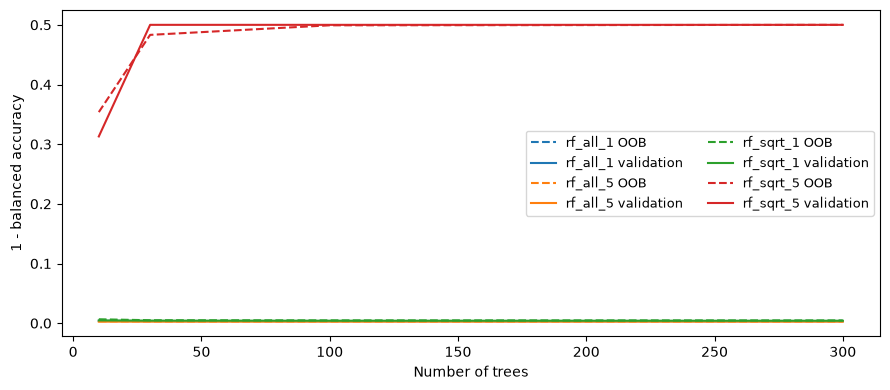

In [3]:
curve_points = [10, 30, 100, 300]
base_leaf = tree_size["min_samples_leaf"]

def oob_error(forest):
    sums = np.zeros((len(y_train), 2))
    votes = np.zeros(len(y_train), dtype=int)
    for tree in forest.estimators_:
        sample = np.random.RandomState(tree.random_state).randint(
            0, len(y_train), len(y_train), dtype=np.int32)
        rows = np.flatnonzero(np.bincount(sample, minlength=len(y_train)) == 0)
        sums[rows] += tree.predict_proba(x_train[rows])
        votes[rows] += 1
    known = votes > 0
    prediction = forest.classes_[sums[known].argmax(axis=1)]
    return 1 - balanced_accuracy_score(y_train[known], prediction), float(known.mean())

forest_rows = pd.read_csv(out / "forest_grid.csv").to_dict("records") if (out / "forest_grid.csv").exists() else []
for mtry in ["all", "sqrt"]:
    for leaf in sorted(set([base_leaf, 5])):
        tag = "rf_" + mtry + "_" + str(leaf)
        state = models / (tag + "_state.pkl")
        forest = load(tag + "_state") if state.exists() else RandomForestClassifier(
            n_estimators=10, max_depth=tree_size["max_depth"], min_samples_leaf=leaf,
            max_features=None if mtry == "all" else "sqrt", bootstrap=True, max_samples=None,
            warm_start=True, n_jobs=THREADS, random_state=SEED)
        forest.set_params(n_jobs=THREADS)
        if not hasattr(forest, "lab_fit_seconds_"):
            forest.lab_fit_seconds_ = 0.0
        completed = len(forest.estimators_) if hasattr(forest, "estimators_") else 0
        counts = sorted(set([completed] + list(range(completed + 10, 301, 10))))
        for count in counts:
            if count == 0:
                continue
            if count > completed:
                progress("forest fitting", configuration=tag, trees=count)
                forest.set_params(n_estimators=count)
                tick = time.perf_counter()
                forest.fit(x_train, y_train)
                forest.lab_fit_seconds_ += time.perf_counter() - tick
                dump(forest, tag + "_state")
                completed = count
            recorded = any(r["configuration"] == tag and r["trees"] == count for r in forest_rows)
            if count in curve_points and not recorded:
                progress("forest OOB and validation", configuration=tag, trees=count)
                error, coverage = oob_error(forest)
                prediction = forest.predict(x_val)
                row = {"configuration": tag, "mtry": mtry, "min_samples_leaf": leaf,
                    "trees": count, "oob_error": error, "oob_coverage": coverage,
                    "validation_error": 1 - balanced_accuracy_score(y_val, prediction),
                    "nodes": sum(int(t.tree_.node_count) for t in forest.estimators_),
                    "fit_seconds": forest.lab_fit_seconds_}
                if count in [100, 300]:
                    dump(forest, tag + "_" + str(count))
                forest_rows.append(row)
                pd.DataFrame(forest_rows).to_csv(out / "forest_grid.csv", index=False)
        del forest
        gc.collect()

forest_table = pd.DataFrame(forest_rows)
candidates = forest_table[forest_table.trees.isin([100, 300])]
def pick_forest(table):
    near = table[table.validation_error <= table.validation_error.min() + TIE]
    return near.sort_values(["trees", "nodes", "configuration"]).iloc[0]
rf_choice = pick_forest(candidates)
bag_choice = pick_forest(candidates[(candidates.mtry == "all") & (candidates.min_samples_leaf == base_leaf)])
rf_tag = rf_choice.configuration + "_" + str(int(rf_choice.trees))
bag_tag = bag_choice.configuration + "_" + str(int(bag_choice.trees))
rf = load(rf_tag).set_params(n_jobs=THREADS)
bagging = load(bag_tag).set_params(n_jobs=THREADS)
dump(rf, "random_forest")
dump(bagging, "bagging")
save(candidates, "forest_candidates")
save(pd.DataFrame([
    {"model": "single tree", "validation_error": 1 - baseline_rows[1]["validation_balanced_accuracy"]},
    {"model": "bagging", "validation_error": bag_choice.validation_error, "trees": int(bag_choice.trees)},
    {"model": "random forest", "validation_error": rf_choice.validation_error, "trees": int(rf_choice.trees)}
]), "tree_bagging_rf_validation")
fig, ax = plt.subplots(figsize=(9, 4))
for tag, group in forest_table.groupby("configuration"):
    group = group.sort_values("trees")
    line = ax.plot(group.trees, group.oob_error, "--", label=tag + " OOB")[0]
    ax.plot(group.trees, group.validation_error, color=line.get_color(), label=tag + " validation")
ax.set(xlabel="Number of trees", ylabel="1 - balanced accuracy")
ax.legend(fontsize=9, ncol=2)
figure("oob_validation_error")


## Part 3a: Standard gradient boosting

Use ordinary `GradientBoostingClassifier` with all 100,000 sampled training rows and all predictors each round. Its built-in early-stopping option would reserve part of training; instead the documented monitor callback evaluates the full external validation set after each stage. The validation margin is updated by only the new tree. The selected model is truncated to its best validation-loss round.

Both curves are actual mean binary cross-entropy. Scikit-learn's internal `train_score_` is deviance (twice log loss in this version), so it is not mislabeled as log loss.


,configuration,learning_rate,max_depth,rounds,fitted_rounds,validation_log_loss,fit_seconds
0,gb_0.03_1,0.03,1,500,500,0.087900,568.146176
1,gb_0.03_3,0.03,3,499,500,0.015455,760.484940
2,gb_0.1_1,0.10,1,500,500,0.035456,600.600317
3,gb_0.1_3,0.10,3,500,500,0.010633,723.794541


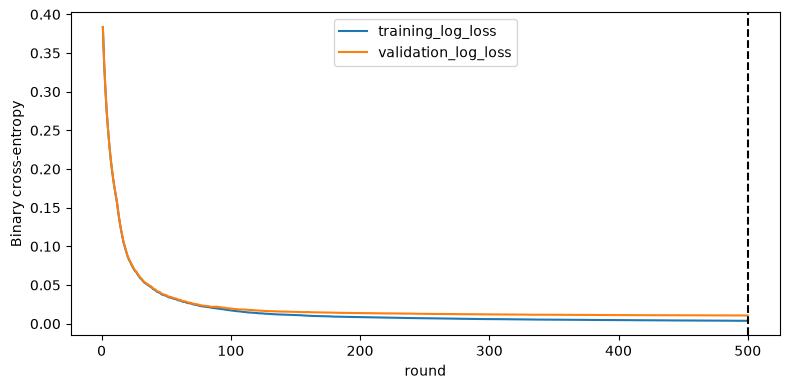

In [4]:
def gb_monitor(iteration, model, state):
    global gb_margin, gb_best, gb_round
    if iteration == 0:
        prior = model.init_.class_prior_[1]
        gb_margin = np.full(len(y_val), np.log(prior / (1 - prior)))
    gb_margin += model.learning_rate * model.estimators_[iteration, 0].predict(x_val)
    p = expit(gb_margin)
    validation_loss = log_loss(y_val, np.c_[1 - p, p])
    train_p = expit(state["raw_predictions"].ravel())
    training_loss = log_loss(y_train, np.c_[1 - train_p, train_p])
    gb_history.append([iteration + 1, training_loss, validation_loss])
    pd.DataFrame(gb_history, columns=["round", "training_log_loss", "validation_log_loss"]).to_csv(
        out / (gb_tag + "_history.csv"), index=False)
    if validation_loss < gb_best:
        gb_best, gb_round = validation_loss, iteration + 1
    if iteration % 10 == 0:
        progress("gradient boosting", configuration=gb_tag, round=iteration + 1, validation_log_loss=validation_loss)
    return iteration + 1 - gb_round >= PATIENCE

gb_rows = []
for eta in [0.03, 0.10]:
    for depth in [1, 3]:
        gb_tag = "gb_" + str(eta) + "_" + str(depth)
        details = out / (gb_tag + ".json")
        if details.exists():
            gb_rows.append(json.loads(details.read_text()))
            continue
        gb_best, gb_round, gb_history = np.inf, 0, []
        model = GradientBoostingClassifier(loss="log_loss", learning_rate=eta, max_depth=depth,
            n_estimators=MAX_ROUNDS, subsample=1.0, max_features=None,
            n_iter_no_change=None, random_state=SEED)
        tick = time.perf_counter()
        model.fit(x_train, y_train, monitor=gb_monitor)
        seconds = time.perf_counter() - tick
        fitted_rounds = len(gb_history)
        model.estimators_ = model.estimators_[:gb_round].copy()
        model.train_score_ = model.train_score_[:gb_round].copy()
        model.n_estimators = model.n_estimators_ = gb_round
        model.lab_fit_seconds_ = seconds
        actual_loss = log_loss(y_val, model.predict_proba(x_val))
        np.testing.assert_allclose(actual_loss, gb_best, atol=1e-9)
        dump(model, gb_tag)
        row = {"configuration": gb_tag, "learning_rate": eta, "max_depth": depth,
            "rounds": gb_round, "fitted_rounds": fitted_rounds,
            "validation_log_loss": actual_loss, "fit_seconds": seconds}
        details.write_text(json.dumps(row, indent=2))
        gb_rows.append(row)
        pd.DataFrame(gb_rows).to_csv(out / "gb_grid.csv", index=False)
        del model
        gc.collect()
gb_table = pd.DataFrame(gb_rows)
gb_choice = gb_table.sort_values(["validation_log_loss", "rounds", "max_depth"]).iloc[0]
gb = load(gb_choice.configuration)
dump(gb, "gradient_boosting")
save(gb_table, "gb_grid")
history = pd.read_csv(out / (gb_choice.configuration + "_history.csv"))
history.plot(x="round", y=["training_log_loss", "validation_log_loss"], figsize=(8, 4))
plt.axvline(int(gb_choice.rounds), color="black", linestyle="--")
plt.ylabel("Binary cross-entropy")
figure("gradient_boosting_loss")


## Part 3b: XGBoost

Fit every combination of eta, depth, lambda, and gamma: **24 configurations**. Every round uses all 100,000 sampled training observations and all predictors. Histograms approximate candidate thresholds. Early stopping uses the full external validation set, patience 20, and retains only the best rounds. Recreate the stateful callback for each fit.

`eval_set` contains training first and validation second, so the stopping dataset is `validation_1`. Training loss is displayed for interpretation, not selection.


,configuration,learning_rate,max_depth,lambda,gamma,rounds,fitted_rounds,validation_log_loss,fit_seconds
0,xgb_0.03_1_0_0,0.03,1,0,0.0,500,500,0.086343,142.581970
1,xgb_0.03_1_0_0.1,0.03,1,0,0.1,500,500,0.086343,152.718003
2,xgb_0.03_1_1_0,0.03,1,1,0.0,500,500,0.086413,147.396582
3,xgb_0.03_1_1_0.1,0.03,1,1,0.1,500,500,0.086413,153.308698
4,xgb_0.03_1_10_0,0.03,1,10,0.0,500,500,0.087034,145.451670
5,xgb_0.03_1_10_0.1,0.03,1,10,0.1,500,500,0.087034,146.901904
6,xgb_0.03_3_0_0,0.03,3,0,0.0,500,500,0.010078,142.695609
7,xgb_0.03_3_0_0.1,0.03,3,0,0.1,500,500,0.010404,160.935027
8,xgb_0.03_3_1_0,0.03,3,1,0.0,500,500,0.010384,166.059227
9,xgb_0.03_3_1_0.1,0.03,3,1,0.1,500,500,0.010577,143.497122


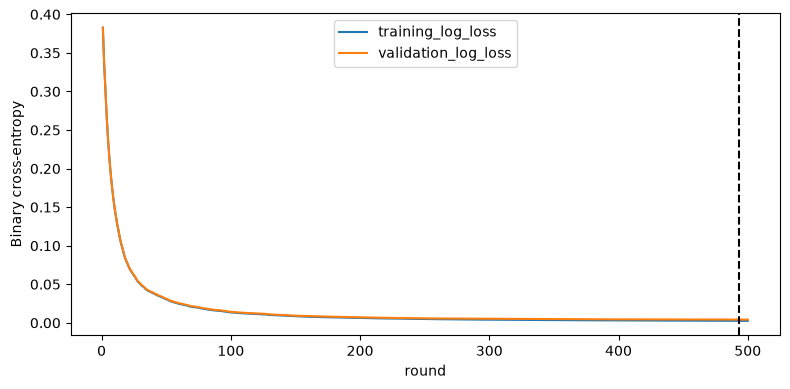

{'bagging': {'configuration': 'rf_all_1_100', 'trees': 100},
 'random_forest': {'configuration': 'rf_all_5_100',
  'trees': 100,
  'mtry': 'all',
  'min_samples_leaf': 5,
  'max_depth': None},
 'gradient_boosting': {'configuration': 'gb_0.1_3',
  'rounds': 500,
  'learning_rate': 0.1,
  'max_depth': 3},
 'xgboost': {'configuration': 'xgb_0.1_3_0_0.1',
  'rounds': 493,
  'learning_rate': 0.1,
  'max_depth': 3,
  'reg_lambda': 0.0,
  'gamma': 0.1}}

In [5]:
xgb_rows = []
for eta in [0.03, 0.10]:
    for depth in [1, 3]:
        for penalty in [0, 1, 10]:
            for gain in [0, 0.1]:
                tag = "xgb_" + "_".join(map(str, [eta, depth, penalty, gain]))
                details = out / (tag + ".json")
                if details.exists():
                    xgb_rows.append(json.loads(details.read_text()))
                    continue
                progress("XGBoost fitting", configuration=tag)
                stop = EarlyStopping(rounds=PATIENCE, metric_name="logloss",
                    data_name="validation_1", maximize=False, save_best=True)
                model = XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                    learning_rate=eta, max_depth=depth, reg_lambda=penalty, gamma=gain,
                    n_estimators=MAX_ROUNDS, tree_method="approx", device="cpu", max_bin=256,
                    subsample=1.0, colsample_bytree=1.0, colsample_bylevel=1.0, colsample_bynode=1.0,
                    n_jobs=THREADS, random_state=SEED, callbacks=[stop])
                tick = time.perf_counter()
                model.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False)
                seconds = time.perf_counter() - tick
                model.lab_fit_seconds_ = seconds
                history = model.evals_result()
                rounds = model.best_iteration + 1
                assert model.get_booster().num_boosted_rounds() == rounds
                p = model.predict_proba(x_val)[:, 1].astype(float)
                loss = log_loss(y_val, np.c_[1 - p, p])
                dump(model, tag)
                pd.DataFrame({"round": np.arange(1, len(history["validation_1"]["logloss"]) + 1),
                    "training_log_loss": history["validation_0"]["logloss"],
                    "validation_log_loss": history["validation_1"]["logloss"]}).to_csv(
                        out / (tag + "_history.csv"), index=False)
                row = {"configuration": tag, "learning_rate": eta, "max_depth": depth,
                    "lambda": penalty, "gamma": gain, "rounds": rounds,
                    "fitted_rounds": len(history["validation_1"]["logloss"]),
                    "validation_log_loss": loss, "fit_seconds": seconds}
                details.write_text(json.dumps(row, indent=2))
                xgb_rows.append(row)
                pd.DataFrame(xgb_rows).to_csv(out / "xgb_grid.csv", index=False)
                del model
                gc.collect()
xgb_table = pd.DataFrame(xgb_rows)
xgb_choice = xgb_table.sort_values(["validation_log_loss", "rounds", "max_depth"]).iloc[0]
boosted = load(xgb_choice.configuration)
dump(boosted, "xgboost")
save(xgb_table, "xgb_grid")
history = pd.read_csv(out / (xgb_choice.configuration + "_history.csv"))
history.plot(x="round", y=["training_log_loss", "validation_log_loss"], figsize=(8, 4))
plt.axvline(int(xgb_choice.rounds), color="black", linestyle="--")
plt.ylabel("Binary cross-entropy")
figure("xgboost_loss")
selection = {
    "bagging": {"configuration": bag_tag, "trees": int(bag_choice.trees)},
    "random_forest": {"configuration": rf_tag, "trees": int(rf_choice.trees), "mtry": rf_choice.mtry,
        "min_samples_leaf": int(rf_choice.min_samples_leaf), "max_depth": tree_size["max_depth"]},
    "gradient_boosting": {"configuration": gb_choice.configuration, "rounds": int(gb_choice.rounds),
        "learning_rate": float(gb_choice.learning_rate), "max_depth": int(gb_choice.max_depth)},
    "xgboost": {"configuration": xgb_choice.configuration, "rounds": int(xgb_choice.rounds),
        "learning_rate": float(xgb_choice.learning_rate), "max_depth": int(xgb_choice.max_depth),
        "reg_lambda": float(xgb_choice["lambda"]), "gamma": float(xgb_choice.gamma)}
}
if (out / "selection_frozen.json").exists():
    assert json.loads((out / "selection_frozen.json").read_text()) == selection
else:
    (out / "selection_frozen.json").write_text(json.dumps(selection, indent=2))
assert len(candidates) == 8 and len(gb_table) == 4 and len(xgb_table) == 24
display(selection)


## Part 4: Final binary comparison

All grids and configurations are frozen above. Evaluate all six models, including the two baselines refitted on the same sampled training rows, on the full original test partition. Save probabilities and reload them on subsequent runs. Test results are never used for tuning.

The ten-error table takes the first ten single-tree test mistakes in saved row order and reports whether RF and XGBoost correct each. These examples are descriptive, not grounds to retune.


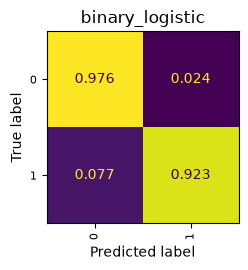

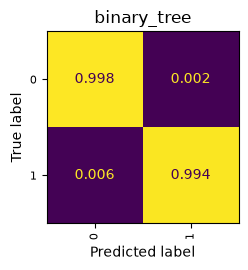

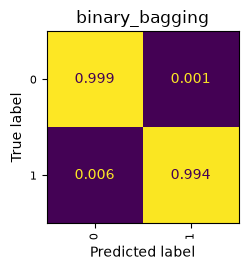

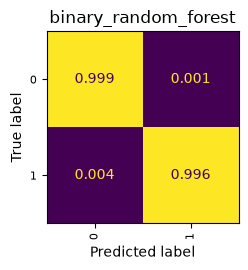

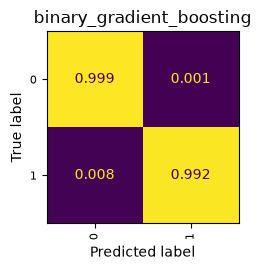

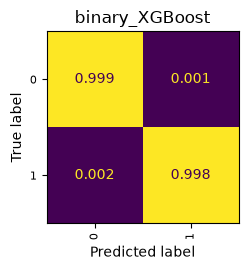

,model,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
0,logistic,0.949346,0.887028,0.922560,0.904445,0.081450
1,tree,0.996102,0.992604,0.993707,0.993155,0.082984
2,bagging,0.996563,0.993448,0.994459,0.993953,0.033279
3,random forest,0.997408,0.993072,0.996227,0.994647,0.013485
4,gradient boosting,0.995498,0.994960,0.992017,0.993486,0.010538
5,XGBoost,0.998379,0.995610,0.997652,0.996630,0.004201


,row_id,true,tree_prediction,rf_prediction,xgb_prediction,rf_corrected,xgb_corrected
0,1283493,0,1,1,1,False,False
1,502283,1,0,0,0,False,False
2,1459686,0,1,1,0,False,True
3,2711653,1,0,1,1,True,True
4,247043,0,1,1,0,False,True
5,360131,1,0,1,1,True,True
6,1284645,0,1,1,1,False,False
7,282410,1,0,1,1,True,True
8,1769475,0,1,1,0,False,True
9,615729,1,0,0,1,False,True


In [6]:
assert (out / "selection_frozen.json").exists()
x_test = sparse.load_npz(inputs / "X_test.npz").astype(np.float32)
y_test = data["test"].binary_label.to_numpy()
test_models = {"logistic": baselines["logistic"], "tree": baselines["tree"],
    "bagging": bagging, "random forest": rf, "gradient boosting": gb, "XGBoost": boosted}
test_rows, predictions = [], {}
for name, model in test_models.items():
    tag = name.replace(" ", "_")
    path = out / (tag + "_test_predictions.csv")
    if path.exists():
        saved = pd.read_csv(path, float_precision="round_trip")
        np.testing.assert_array_equal(saved.row_id, data["test"].row_id)
        p = saved.attack_probability.to_numpy()
    else:
        progress("final test evaluation", model=name)
        p = model.predict_proba(x_test)[:, 1]
    p = np.asarray(p, dtype=float)
    probability = np.c_[1 - p, p]
    prediction = (p > 0.5).astype(int)
    predictions[name] = prediction
    if not path.exists():
        pd.DataFrame({"row_id": data["test"].row_id, "true": y_test, "predicted": prediction,
            "attack_probability": p}).to_csv(path, index=False)
    report = classification_report(y_test, prediction, output_dict=True, zero_division=0)["1"]
    test_rows.append({"model": name, "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
        "attack_precision": report["precision"], "attack_recall": report["recall"],
        "attack_f1": report["f1-score"], "log_loss": log_loss(y_test, probability)})
    confusion(y_test, prediction, "binary_" + tag)
save(pd.DataFrame(test_rows), "binary_test_results")
wrong = np.flatnonzero(predictions["tree"] != y_test)[:10]
assert len(wrong) == 10
save(pd.DataFrame({"row_id": data["test"].row_id.iloc[wrong].to_numpy(), "true": y_test[wrong],
    "tree_prediction": predictions["tree"][wrong], "rf_prediction": predictions["random forest"][wrong],
    "xgb_prediction": predictions["XGBoost"][wrong],
    "rf_corrected": predictions["random forest"][wrong] == y_test[wrong],
    "xgb_corrected": predictions["XGBoost"][wrong] == y_test[wrong]}), "ten_tree_errors")


## Part 4 continued: RF importance

MDI is saved for individual encoded columns and for raw-feature groups. The grouped permutation ranking considers **every eligible numerical feature and the complete destination-port block**, with three fixed permutations of all validation rows. No validation row sample is used. A correlated substitute can hide a feature's permutation effect, and split-based MDI can favor features with many possible splits. Neither ranking establishes a causal attack mechanism.

Each feature/repeat is checkpointed so completed importance calculations are reused after interruption.


,encoded_feature,MDI
11,numeric__Bwd Packet Length Std,0.519277
31,numeric__Bwd Header Length,0.119522
35,numeric__Max Packet Length,0.112325
48,numeric__Average Packet Size,0.106756
96,port__Destination Port_80.0,0.021369
30,numeric__Fwd Header Length,0.019726
55,numeric__Init_Win_bytes_forward,0.016512
7,numeric__Fwd Packet Length Std,0.011055
80,port__Destination Port_21.0,0.010897
147,port__Destination Port_443.0,0.006898


,feature,MDI,mean,std,count
0,Flow Duration,0.001920,-1.463485e-05,1.969734e-05,3
1,Total Fwd Packets,0.000347,5.299889e-07,9.179677e-07,3
2,Total Backward Packets,0.000739,-5.299889e-07,9.179677e-07,3
3,Total Length of Bwd Packets,0.000341,-3.057031e-06,9.416898e-06,3
4,Fwd Packet Length Max,0.000903,1.565386e-05,8.731174e-06,3
...,...,...,...,...,...
64,Idle Std,0.000006,0.000000e+00,0.000000e+00,3
65,Idle Max,0.000076,-4.157976e-06,8.615534e-06,3
66,Idle Min,0.003892,3.671602e-03,4.309137e-05,3
67,Total Length of Fwd Packets,0.000521,2.477709e-04,5.040946e-06,3


,feature,MDI,mean,std,count
11,Bwd Packet Length Std,0.519277,0.221669,0.000141,3
31,Bwd Header Length,0.119522,0.121487,0.000167,3
35,Max Packet Length,0.112325,0.033578,0.000312,3
48,Average Packet Size,0.106756,0.139906,0.000256,3
68,Destination Port,0.044911,0.321301,0.000622,3
30,Fwd Header Length,0.019726,0.009826,0.000058,3
55,Init_Win_bytes_forward,0.016512,0.102450,0.000759,3
7,Fwd Packet Length Std,0.011055,0.060795,0.000882,3
33,Bwd Packets/s,0.006163,0.010146,0.000086,3
22,Fwd IAT Min,0.005188,0.003330,0.000014,3


,feature,MDI,mean,std,count
68,Destination Port,0.044911,0.321301,0.000622,3
11,Bwd Packet Length Std,0.519277,0.221669,0.000141,3
48,Average Packet Size,0.106756,0.139906,0.000256,3
31,Bwd Header Length,0.119522,0.121487,0.000167,3
55,Init_Win_bytes_forward,0.016512,0.102450,0.000759,3
7,Fwd Packet Length Std,0.011055,0.060795,0.000882,3
35,Max Packet Length,0.112325,0.033578,0.000312,3
33,Bwd Packets/s,0.006163,0.010146,0.000086,3
30,Fwd Header Length,0.019726,0.009826,0.000058,3
66,Idle Min,0.003892,0.003672,0.000043,3


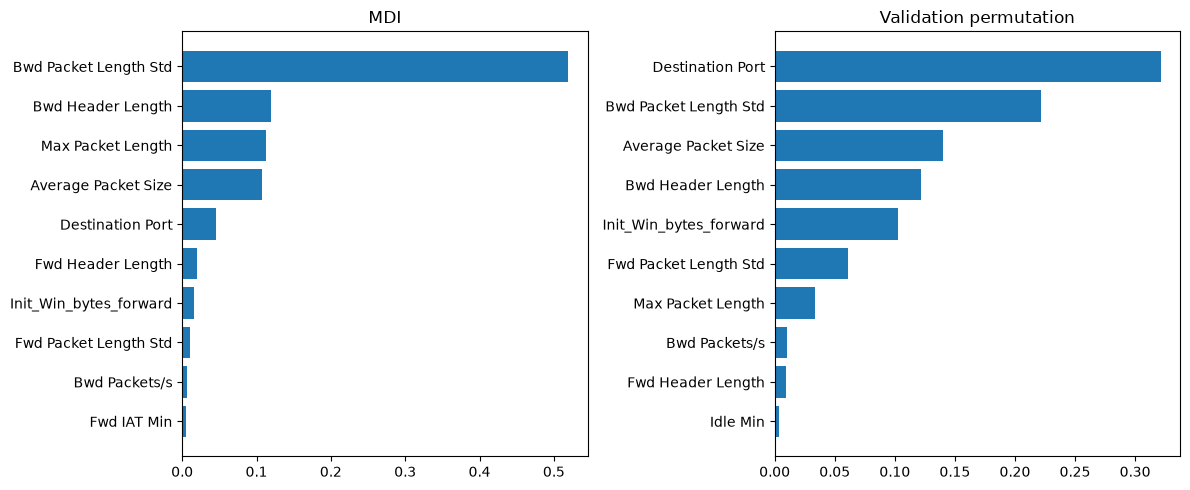

5215

In [7]:
raw_names = [name.split("__", 1)[1] for name in features[:n_numeric]] + ["Destination Port"]
raw_mdi = np.r_[rf.feature_importances_[:n_numeric], rf.feature_importances_[n_numeric:].sum()]
mdi = pd.DataFrame({"feature": raw_names, "MDI": raw_mdi})
save(pd.DataFrame({"encoded_feature": features, "MDI": rf.feature_importances_}).nlargest(10, "MDI"),
     "rf_mdi_encoded_top10")
numeric = x_val[:, :n_numeric].toarray()
ports = x_val[:, n_numeric:]
base_score = balanced_accuracy_score(y_val, rf.predict(x_val))
path = out / "rf_permutation_runs.csv"
permutations = pd.read_csv(path).to_dict("records") if path.exists() else []
for index, feature in enumerate(raw_names):
    for repeat in range(3):
        if any(r["feature"] == feature and r["repeat"] == repeat for r in permutations):
            continue
        progress("validation permutation importance", feature=feature, repeat=repeat)
        order = np.random.default_rng(SEED + repeat).permutation(len(y_val))
        if index == n_numeric:
            altered = sparse.hstack([sparse.csr_matrix(numeric), ports[order]], format="csr")
        else:
            changed = numeric.copy()
            changed[:, index] = numeric[order, index]
            altered = sparse.hstack([sparse.csr_matrix(changed), ports], format="csr")
        score = balanced_accuracy_score(y_val, rf.predict(altered))
        permutations.append({"feature": feature, "repeat": repeat, "score_drop": base_score - score})
        pd.DataFrame(permutations).to_csv(path, index=False)
        del altered
        gc.collect()
summary = pd.DataFrame(permutations).groupby("feature").score_drop.agg(["mean", "std", "count"]).reset_index()
assert len(summary) == len(raw_names) and (summary["count"] == 3).all()
importance = mdi.merge(summary, on="feature")
save(importance, "rf_importance_all_raw_features")
save(importance.nlargest(10, "MDI"), "rf_mdi_top10")
save(importance.nlargest(10, "mean"), "rf_permutation_top10")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title in zip(axes, ["MDI", "mean"], ["MDI", "Validation permutation"]):
    table = importance.nlargest(10, column).sort_values(column)
    ax.barh(table.feature, table[column])
    ax.set_title(title)
figure("rf_importance_rankings")
del numeric, ports
gc.collect()


## Part 5: Multiclass with and without port

Retain the same categories as Lab 2. Refit a clone of the complete preprocessor **only on retained training rows**, preserving Lab 2's eligible-feature and log decisions. The numerical part of that fitted transformer supplies the no-port representation, so both representations use identical numerical transformations.

Keep the selected binary RF/XGBoost hyperparameters. An RF sqrt(d) policy remains sqrt of the representation's current encoded dimension; an all-d policy remains all predictors. Only the XGBoost round count is chosen again on the multiclass validation set, with the same 500-round ceiling and patience 20. All four multiclass models are fixed before their test predictions are computed.

Prepared matrices, fitted models, row-aligned probabilities, and score tables are saved. This is not a new random split.


In [8]:
del x_train, x_val, x_test
gc.collect()
multi_classes = manifest["multiclass_categories"]
encoder = LabelEncoder().fit(multi_classes)
multi_labels = {}
for part, labels in data.items():
    rows = labels[labels.multiclass_label.isin(multi_classes)].copy()
    rows["target"] = encoder.transform(rows.multiclass_label)
    multi_labels[part] = rows
    rows.to_csv(out / ("multiclass_" + part + "_labels.csv"), index=False)
cache = out / "multiclass_inputs_complete.json"
if not cache.exists():
    progress("fit multiclass preprocessing on retained training rows")
    files = sorted((source / "MachineLearningCVE").glob("*.csv"))
    raw = pd.concat([pd.read_csv(f).rename(columns=str.strip) for f in files], ignore_index=True)
    assert len(raw) == manifest["raw_rows"]
    with (inputs / "preprocessor.pkl").open("rb") as file:
        multi_prep = clone(cloudpickle.load(file))
    rows = multi_labels["train"].row_id.to_numpy()
    np.testing.assert_array_equal(raw.loc[rows, "Label"], multi_labels["train"].multiclass_label)
    multi_prep.fit(raw.loc[rows].replace([np.inf, -np.inf], np.nan))
    for part, labels in multi_labels.items():
        rows = labels.row_id.to_numpy()
        np.testing.assert_array_equal(raw.loc[rows, "Label"], labels.multiclass_label)
        matrix = multi_prep.transform(raw.loc[rows].replace([np.inf, -np.inf], np.nan)).astype(np.float32)
        sparse.save_npz(out / ("multiclass_with_port_" + part + ".npz"), matrix)
    dump(multi_prep, "multiclass_preprocessor")
    cache.write_text(json.dumps({"status": "complete", "classes": multi_classes}, indent=2))
    del raw, matrix, multi_prep
    gc.collect()

multi_settings = []
for representation in ["without_port", "with_port"]:
    matrices = [sparse.load_npz(out / ("multiclass_with_port_" + part + ".npz"))
                for part in ["train", "validation"]]
    if representation == "without_port":
        matrices = [m[:, :n_numeric] for m in matrices]
    a, b = matrices
    train_target = multi_labels["train"].target.to_numpy()
    val_target = multi_labels["validation"].target.to_numpy()
    rf_name = "multiclass_rf_" + representation
    state = models / (rf_name + "_state.pkl")
    model = load(rf_name + "_state") if state.exists() else clone(rf).set_params(n_estimators=10, warm_start=True)
    if not hasattr(model, "lab_fit_seconds_"):
        model.lab_fit_seconds_ = 0.0
    completed = len(model.estimators_) if hasattr(model, "estimators_") else 0
    for count in range(completed + 10, int(rf_choice.trees) + 1, 10):
        progress("multiclass forest fitting", representation=representation, trees=count)
        model.set_params(n_estimators=count)
        tick = time.perf_counter()
        model.fit(a, train_target)
        model.lab_fit_seconds_ += time.perf_counter() - tick
        dump(model, rf_name + "_state")
    assert len(model.estimators_) == int(rf_choice.trees)
    dump(model, rf_name)
    multi_settings.append({"model": "random forest", "representation": representation,
        "trees": int(rf_choice.trees), "encoded_predictors": a.shape[1], "fit_seconds": model.lab_fit_seconds_})
    del model
    name = "multiclass_xgb_" + representation
    details = out / (name + ".json")
    if details.exists():
        row = json.loads(details.read_text())
    else:
        progress("multiclass XGBoost fitting", representation=representation)
        stop = EarlyStopping(rounds=PATIENCE, metric_name="mlogloss",
            data_name="validation_1", maximize=False, save_best=True)
        params = selection["xgboost"]
        model = XGBClassifier(objective="multi:softprob", num_class=len(encoder.classes_), eval_metric="mlogloss",
            learning_rate=params["learning_rate"], max_depth=params["max_depth"],
            reg_lambda=params["reg_lambda"], gamma=params["gamma"], n_estimators=MAX_ROUNDS,
            tree_method="approx", device="cpu", max_bin=256, subsample=1.0,
            colsample_bytree=1.0, colsample_bylevel=1.0, colsample_bynode=1.0,
            n_jobs=THREADS, random_state=SEED, callbacks=[stop])
        tick = time.perf_counter()
        model.fit(a, train_target, eval_set=[(a, train_target), (b, val_target)], verbose=False)
        model.lab_fit_seconds_ = time.perf_counter() - tick
        rounds = model.best_iteration + 1
        dump(model, name)
        history = model.evals_result()
        pd.DataFrame({"round": np.arange(1, len(history["validation_1"]["mlogloss"]) + 1),
            "training_log_loss": history["validation_0"]["mlogloss"],
            "validation_log_loss": history["validation_1"]["mlogloss"]}).to_csv(
                out / (name + "_history.csv"), index=False)
        row = {"model": "XGBoost", "representation": representation, "rounds": rounds,
            "encoded_predictors": a.shape[1], "fit_seconds": model.lab_fit_seconds_,
            "validation_log_loss": float(history["validation_1"]["mlogloss"][rounds - 1])}
        details.write_text(json.dumps(row, indent=2))
        del model
    multi_settings.append(row)
    del a, b, matrices
    gc.collect()
save(pd.DataFrame(multi_settings), "multiclass_settings")
(out / "multiclass_selection_frozen.json").write_text(json.dumps(multi_settings, indent=2))


,model,representation,trees,encoded_predictors,fit_seconds,rounds,validation_log_loss
0,random forest,without_port,100.0,68,32.188212,NaN,NaN
1,XGBoost,without_port,NaN,68,108.611550,331.0,0.006537
2,random forest,with_port,100.0,13759,30.030018,NaN,NaN
3,XGBoost,with_port,NaN,13759,182.559921,268.0,0.005562


736

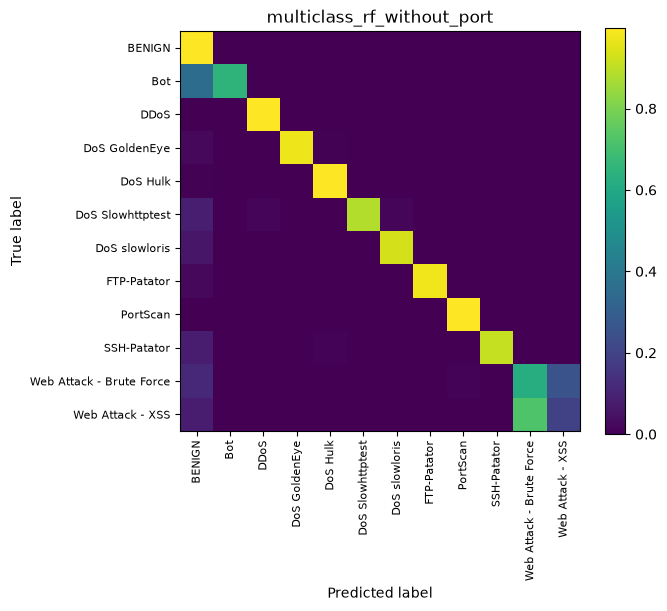

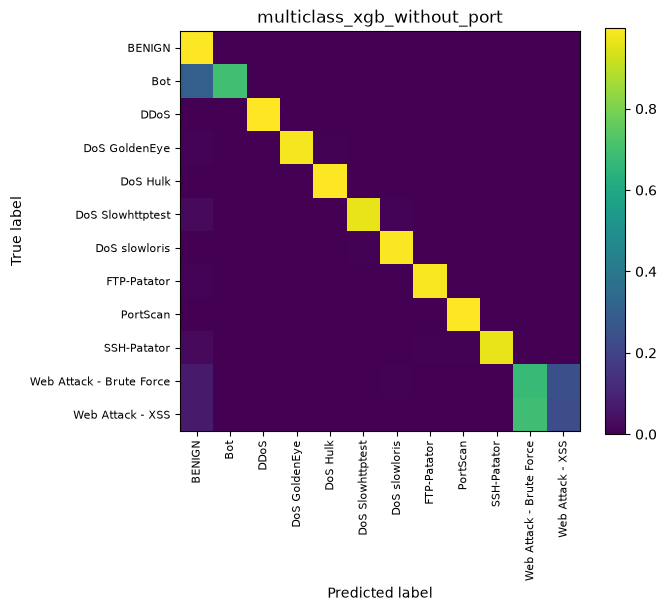

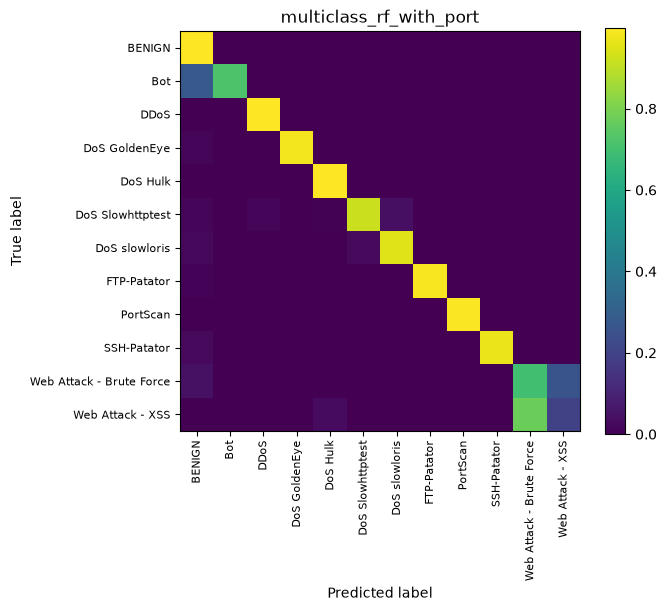

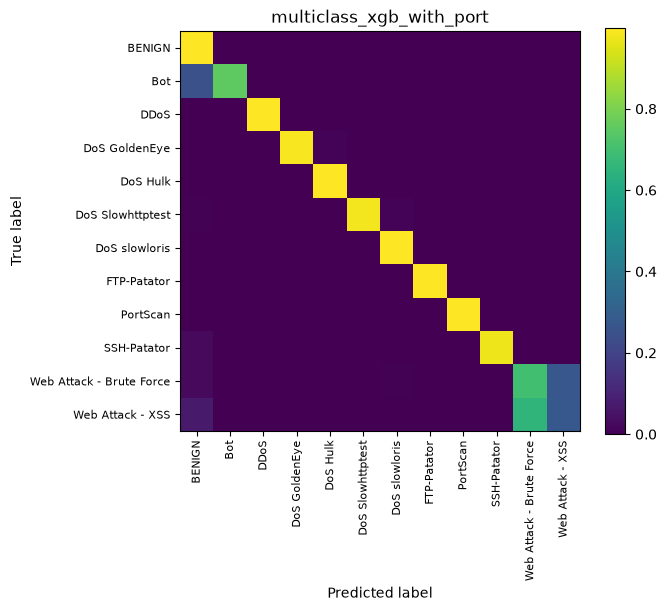

,model,representation,macro_f1,log_loss
0,random forest,without_port,0.859226,0.018394
1,XGBoost,without_port,0.882872,0.006655
2,random forest,with_port,0.872038,0.015557
3,XGBoost,with_port,0.893198,0.005771


,model,representation,class,recall
0,random forest,without_port,BENIGN,0.998661
1,random forest,without_port,Bot,0.648464
2,random forest,without_port,DDoS,0.997292
3,random forest,without_port,DoS GoldenEye,0.974076
4,random forest,without_port,DoS Hulk,0.995333
5,random forest,without_port,DoS Slowhttptest,0.885204
6,random forest,without_port,DoS slowloris,0.935644
7,random forest,without_port,FTP-Patator,0.976404
8,random forest,without_port,PortScan,0.995742
9,random forest,without_port,SSH-Patator,0.910973


representation,model,class,with_port,without_port,port_gain
22,random forest,Web Attack � Brute Force,0.695455,0.622727,0.072727
13,random forest,Bot,0.720137,0.648464,0.071672
21,random forest,SSH-Patator,0.971014,0.910973,0.060041
1,XGBoost,Bot,0.750853,0.696246,0.054608
11,XGBoost,Web Attack � XSS,0.275510,0.234694,0.040816
17,random forest,DoS Slowhttptest,0.919643,0.885204,0.034439
10,XGBoost,Web Attack � Brute Force,0.695455,0.677273,0.018182
18,random forest,DoS slowloris,0.951733,0.935644,0.016089
5,XGBoost,DoS Slowhttptest,0.980867,0.965561,0.015306
19,random forest,FTP-Patator,0.991011,0.976404,0.014607


In [9]:
multi_results, recall_rows = [], []
truth = multi_labels["test"].target.to_numpy()
for representation in ["without_port", "with_port"]:
    matrix = sparse.load_npz(out / "multiclass_with_port_test.npz")
    if representation == "without_port":
        matrix = matrix[:, :n_numeric]
    for family, prefix in [("random forest", "rf"), ("XGBoost", "xgb")]:
        name = "multiclass_" + prefix + "_" + representation
        model = load(name)
        path = out / (name + "_predictions.csv")
        if path.exists():
            saved = pd.read_csv(path, float_precision="round_trip")
            np.testing.assert_array_equal(saved.row_id, multi_labels["test"].row_id)
            probability = saved[[str(c) for c in encoder.classes_]].to_numpy()
        else:
            progress("multiclass final test", model=family, representation=representation)
            probability = model.predict_proba(matrix).astype(float)
            probability /= probability.sum(axis=1, keepdims=True)
            saved = pd.DataFrame(probability, columns=encoder.classes_)
            saved.insert(0, "row_id", multi_labels["test"].row_id.to_numpy())
            saved.to_csv(path, index=False)
        prediction = probability.argmax(axis=1)
        report = classification_report(truth, prediction, labels=np.arange(len(encoder.classes_)),
            output_dict=True, zero_division=0)
        multi_results.append({"model": family, "representation": representation,
            "macro_f1": report["macro avg"]["f1-score"], "log_loss": log_loss(truth, probability)})
        recall_rows.extend([[family, representation, label, report[str(i)]["recall"]]
                            for i, label in enumerate(encoder.classes_)])
        confusion(encoder.inverse_transform(truth), encoder.inverse_transform(prediction), name,
                  labels=encoder.classes_)
        del model
    del matrix
    gc.collect()
save(pd.DataFrame(multi_results), "multiclass_results")
recall = pd.DataFrame(recall_rows, columns=["model", "representation", "class", "recall"])
save(recall, "multiclass_recall")
effect = recall.pivot(index=["model", "class"], columns="representation", values="recall").reset_index()
effect["port_gain"] = effect.with_port - effect.without_port
save(effect.sort_values("port_gain", ascending=False), "multiclass_port_effect")


## Part 6: Computational cost and recommendation

Refit the fixed single-tree configuration to measure it under this run's hardware/thread conditions and confirm its validation predictions match the reference. This does not retune it or compute new baseline test scores.

For tree/RF/GB/XGBoost, time prediction on the same first 10,000 validation flows (or all available rows in the synthetic check), using three repeats and reporting the median. This probe size affects timing only, not training or score evaluation. Model sizes use the same cloudpickle format. Report selected-model tree counts separately from boosting rounds actually fitted before early stopping, and report full search cost separately from selected-fit cost.


In [10]:
x_train = sparse.load_npz(inputs / "X_train.npz")[chosen].astype(np.float32)
x_val = sparse.load_npz(inputs / "X_validation.npz").astype(np.float32)
progress("single-tree cost reference fit")
tick = time.perf_counter()
reference = DecisionTreeClassifier(max_depth=tree_size["max_depth"],
    min_samples_leaf=tree_size["min_samples_leaf"], random_state=SEED).fit(x_train, y_train)
reference.lab_fit_seconds_ = time.perf_counter() - tick
np.testing.assert_allclose(reference.predict_proba(x_val), baselines["tree"].predict_proba(x_val), atol=1e-12)
dump(reference, "single_tree_cost_reference")
progress("selected forest cost reference fit")
tick = time.perf_counter()
cost_rf = clone(rf).set_params(warm_start=False, n_jobs=THREADS).fit(x_train, y_train)
cost_rf.lab_fit_seconds_ = time.perf_counter() - tick
np.testing.assert_allclose(cost_rf.predict_proba(x_val), rf.predict_proba(x_val), atol=1e-12)
cost_rows = []
probe = x_val[:min(10000, x_val.shape[0])]
for name, model in [("single tree", reference), ("random forest", cost_rf),
                    ("gradient boosting", gb), ("XGBoost", boosted)]:
    times = []
    for repeat in range(3):
        tick = time.perf_counter()
        model.predict_proba(probe)
        times.append(time.perf_counter() - tick)
    tag = "cost_" + name.replace(" ", "_")
    dump(model, tag)
    trees = model.get_booster().num_boosted_rounds() if name == "XGBoost" else (
        int(model.estimators_.size) if name == "gradient boosting" else
        len(model.estimators_) if name == "random forest" else 1)
    rounds_fitted = int(xgb_choice.fitted_rounds) if name == "XGBoost" else (
        int(gb_choice.fitted_rounds) if name == "gradient boosting" else trees)
    cost_rows.append({"model": name, "selected_fit_seconds": model.lab_fit_seconds_,
        "prediction_rows": probe.shape[0], "median_prediction_seconds": float(np.median(times)),
        "serialized_bytes": (models / (tag + ".pkl")).stat().st_size,
        "trees_in_selected_model": trees, "trees_fitted_before_early_stop": rounds_fitted})
save(pd.DataFrame(cost_rows), "computational_cost")
search_cost = {"forests_unique_fit_seconds": float(forest_table.groupby("configuration").fit_seconds.max().sum()),
    "gradient_boosting_search_seconds": float(gb_table.fit_seconds.sum()),
    "xgboost_search_seconds": float(xgb_table.fit_seconds.sum())}
(out / "search_cost.json").write_text(json.dumps(search_cost, indent=2))
receipt = {"status": "complete", "binary_models": len(test_rows), "forest_grid_rows": len(candidates),
    "gb_grid_rows": len(gb_table), "xgb_grid_rows": len(xgb_table), "multiclass_models": len(multi_results),
    "training_rows": len(y_train), "validation_rows": len(y_val), "test_rows": len(y_test),
    "encoded_predictors": d, "permutation_features": len(importance), "permutation_repeats": 3,
    "threads": THREADS, "seed": SEED, "python": platform.python_version(),
    "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "hardware": platform.platform(), "data_scope": manifest["data_scope"]}
assert receipt["binary_models"] == 6 and receipt["forest_grid_rows"] == 8
assert receipt["gb_grid_rows"] == 4 and receipt["xgb_grid_rows"] == 24 and receipt["multiclass_models"] == 4
(out / "completion.json").write_text(json.dumps(receipt, indent=2))
display(receipt)


,model,selected_fit_seconds,prediction_rows,median_prediction_seconds,serialized_bytes,trees_in_selected_model,trees_fitted_before_early_stop
0,single tree,6.956228,10000,0.000782,46049,1,1
1,random forest,26.805596,10000,0.013218,2539029,100,100
2,gradient boosting,723.794541,10000,0.050480,623699,500,500
3,XGBoost,163.825958,10000,0.018423,562819,493,500


{'status': 'complete',
 'binary_models': 6,
 'forest_grid_rows': 8,
 'gb_grid_rows': 4,
 'xgb_grid_rows': 24,
 'multiclass_models': 4,
 'training_rows': 100000,
 'validation_rows': 378354,
 'test_rows': 378355,
 'encoded_predictors': 49757,
 'permutation_features': 69,
 'permutation_repeats': 3,
 'threads': 12,
 'seed': 42,
 'python': '3.13.15',
 'sklearn': '1.9.1',
 'xgboost': '3.4.1',
 'numpy': '2.5.3',
 'pandas': '3.0.6',
 'scipy': '1.18.1',
 'hardware': 'macOS-15.3.1-arm64-arm-64bit-Mach-O',
 'data_scope': '100000 stratified training rows; full validation and test sets'}

## Discussion of the measured results

These measurements use 100,000 training rows, full original binary validation/test partitions, and seed 42.

1. **Tree, bagging and RF.** Test attack F1 increases from 0.9932 for one tree to 0.9940 for bagging and 0.9946 for the selected RF. Both selected ensembles have 100 trees. RF uses all predictors and minimum leaf size five, so random feature selection did not improve this comparison. The larger leaf-size setting distinguishes it from bagging. The square-root/leaf-five candidate predicts only benign on validation, giving balanced accuracy 0.5. The fairly flat OOB/validation curves support choosing the smaller model. One seed does not measure variance across repeated experiments.
2. **Boosting.** Both selected boosters use learning rate 0.10 and depth three. GB retains 500 rounds; XGBoost retains 493, with lambda zero and gamma 0.1. XGBoost test F1 is 0.9966 versus GB's 0.9935; log loss is 0.0042 versus 0.0105. The selected XGBoost model has no L2 leaf penalty. Its split-gain constraint, update rule and approximate split search still differ from GB; these results do not isolate one cause of the score gap. For GB stumps at 500 rounds, validation loss is 0.0879 at learning rate 0.03 and 0.0355 at rate 0.10.
3. **Ten mistakes.** RF corrects three and XGBoost corrects seven of the first ten single-tree test mistakes in saved row order. These examples are descriptive, not an unbiased estimate of correction rates.
4. **Importance.** Destination port ranks fifth by grouped MDI and first by permutation importance. Shuffling its complete one-hot block lowers validation balanced accuracy by about 0.3213. MDI credits training splits; permutation measures disrupted validation predictions. Correlated substitutes can hide permutation effects. Predictive importance is not causality.
5. **Multiclass and port.** RF macro-F1 rises from 0.8592 to 0.8720 with port; XGBoost rises from 0.8829 to 0.8932. RF recall gains are largest for Web Attack - Brute Force (+7.27 percentage points), Bot (+7.17) and SSH-Patator (+6.00). XGBoost gains most for Bot (+5.46) and Web Attack - XSS (+4.08). Services may help identify attacks, but ports can also identify tools, victims or capture scenarios. Gains are not uniform across classes. We retain the same twelve categories as full Lab 2 despite smaller sampled training counts.
6. **Recommendation.** For nightly batch screening of similar captures, where a few minutes of retraining is acceptable, I would choose XGBoost for its measured attack F1 and log loss. RF fits faster and may suit more frequent updates. The cost table measures classifiers on prepared features and lists model sizes and retained/fitted tree counts. Ensembles are harder to interpret than one tree.
7. **Limits.** This is a fixed random-split CICIDS2017 comparison using 100,000 training rows, not all 1,765,653. The binary preprocessor is reused from the original full Lab 2 training partition; multiclass preprocessing is refitted on its retained sampled training rows. The results do not establish performance on a new organization.

Tables, plots, selected settings, sampled row IDs and prediction caches are saved in `notebook_results/`. The separate LaTeX report is generated from these verified results by `build_report.py`.
